# Feed Type Recommendation System using PCA and Similarity Metrics

**Business Context:** An agricultural supply company wants to recommend similar feed types to farmers based on observed performance (weight gain).


## Business Understanding

### Problem Statement
The company needs a data-driven way to surface comparable products rather than relying solely on salesperson intuition or simple average-weight ranking.

### Business Objectives
- Increase cross-sell / up-sell of alternative feed products that deliver similar performance profiles.
- Reduce the risk of recommending a feed that produces markedly different results (which could damage trust).
- Provide transparent, explainable recommendations that sales teams can communicate to farmers.
- Support inventory and assortment decisions by identifying clusters of interchangeable products.

### Success Metrics (Business)
- Recommendation acceptance rate (farmer tries suggested alternative).
- Retention / satisfaction after switching to a recommended feed.
- Reduction in returns or complaints related to unexpected performance differences.

### Analytical Approach
We treat each **feed type** as a product.  
From the distribution of chicken weights produced by that feed we engineer a feature vector (mean, std, quantiles, etc.).  
PCA reduces these features to a low-dimensional space that captures the main axes of performance variation.  
Cosine and Euclidean similarities in that space are then used to rank the most similar alternative feeds.

## **Stakeholders**

1. Famrers: They will get a reliable weight-gain performance; cost-effective alternatives when a preferred feed is unavailable or expensive.
2. Sales: Equip them with the credible talking points and product comparisons.
3. Management of the feeds company: Data driven levers and risk reduction


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine, euclidean, pdist, squareform
from scipy.linalg import svd
from scipy import stats

## Data Understanding and loading


In [15]:
# Load the data (place chickwts.csv in the same folder as this notebook)
df = pd.read_csv("chickwts.csv")
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])   # drop an R-style index column if present
df["feed"] = df["feed"].astype(str)

print("Shape:", df.shape)
print("\nFirst 10 rows:")
display(df.head(10))
print("\nData types and missing values:")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
print("Duplicate rows (identical weight and feed can occur naturally):", df.duplicated().sum())
print("\nBirds per feed:")
print(df["feed"].value_counts())

Shape: (71, 2)

First 10 rows:


,weight,feed
0,179,horsebean
1,160,horsebean
2,136,horsebean
3,227,horsebean
4,217,horsebean
5,168,horsebean
6,108,horsebean
7,124,horsebean
8,143,horsebean
9,140,horsebean



Data types and missing values:


,dtype,missing
weight,int64,0
feed,object,0


Duplicate rows (identical weight and feed can occur naturally): 1

Birds per feed:
feed
soybean      14
linseed      12
sunflower    12
casein       12
meatmeal     11
horsebean    10
Name: count, dtype: int64


The dataset has 71 birds and two columns (weight in grams and feed type) with no missing values. There are six feeds with 10 to 14 birds each (soybean 14, linseed, sunflower and casein 12, meatmeal 11, horsebean 10). One row repeats another (same feed and weight); with weights recorded in whole grams that is plausible, so it is kept. The samples are small, which means every statistic computed per feed, and especially skewness, kurtosis and extreme values, is a noisy estimate.

In [16]:
summary = df.groupby("feed")["weight"].agg(
    count="count",
    mean="mean",
    std="std",
    min="min",
    q25=lambda x: x.quantile(0.25),
    median="median",
    q75=lambda x: x.quantile(0.75),
    max="max",
    skew=lambda x: x.skew(),
    kurt=lambda x: x.kurt(),
).round(2).sort_values("mean", ascending=False)

feed_order = summary.index.tolist()          # best to worst by mean weight
print("Performance profile by feed type (sorted by mean weight):")
summary

Performance profile by feed type (sorted by mean weight):


,count,mean,std,min,q25,median,q75,max,skew,kurt
feed,,,,,,,,,,
sunflower,12,328.92,48.84,226,312.75,328.0,340.25,423,-0.07,1.75
casein,12,323.58,64.43,216,277.25,342.0,370.75,404,-0.60,-0.96
meatmeal,11,276.91,64.90,153,249.50,263.0,320.00,380,-0.33,0.01
soybean,14,246.43,54.13,158,206.75,248.0,270.00,329,0.04,-0.71
linseed,12,218.75,52.24,141,178.00,221.0,257.75,309,0.01,-0.88
horsebean,10,160.20,38.63,108,137.00,151.5,176.25,227,0.65,-0.40


Sunflower (329 g) and casein (324 g) give the heaviest birds, followed by meatmeal (277 g), soybean (246 g), linseed (219 g) and horsebean (160 g). Average weight hides differences in reliability:

* **Sunflower is the most consistent feed** in relative terms (CV 14.9%, IQR only 27.5 g). Its kurtosis (1.75) shows that most birds are tightly bunched, with a few extreme ones.
* **Casein is as variable as meatmeal** (standard deviation about 64 to 65 g), with an IQR of 93.5 g and a negative skew (-0.60), meaning a tail of poorly performing birds.
* **Horsebean** has the lowest absolute spread (standard deviation 38.6 g) but the highest relative variability (CV 24.1%), because its average is low.

Two feeds with almost the same average (sunflower and casein) therefore differ clearly in how predictable they are. This is why a profile richer than the mean was considered, and why we later test whether the extra statistics help or hurt.

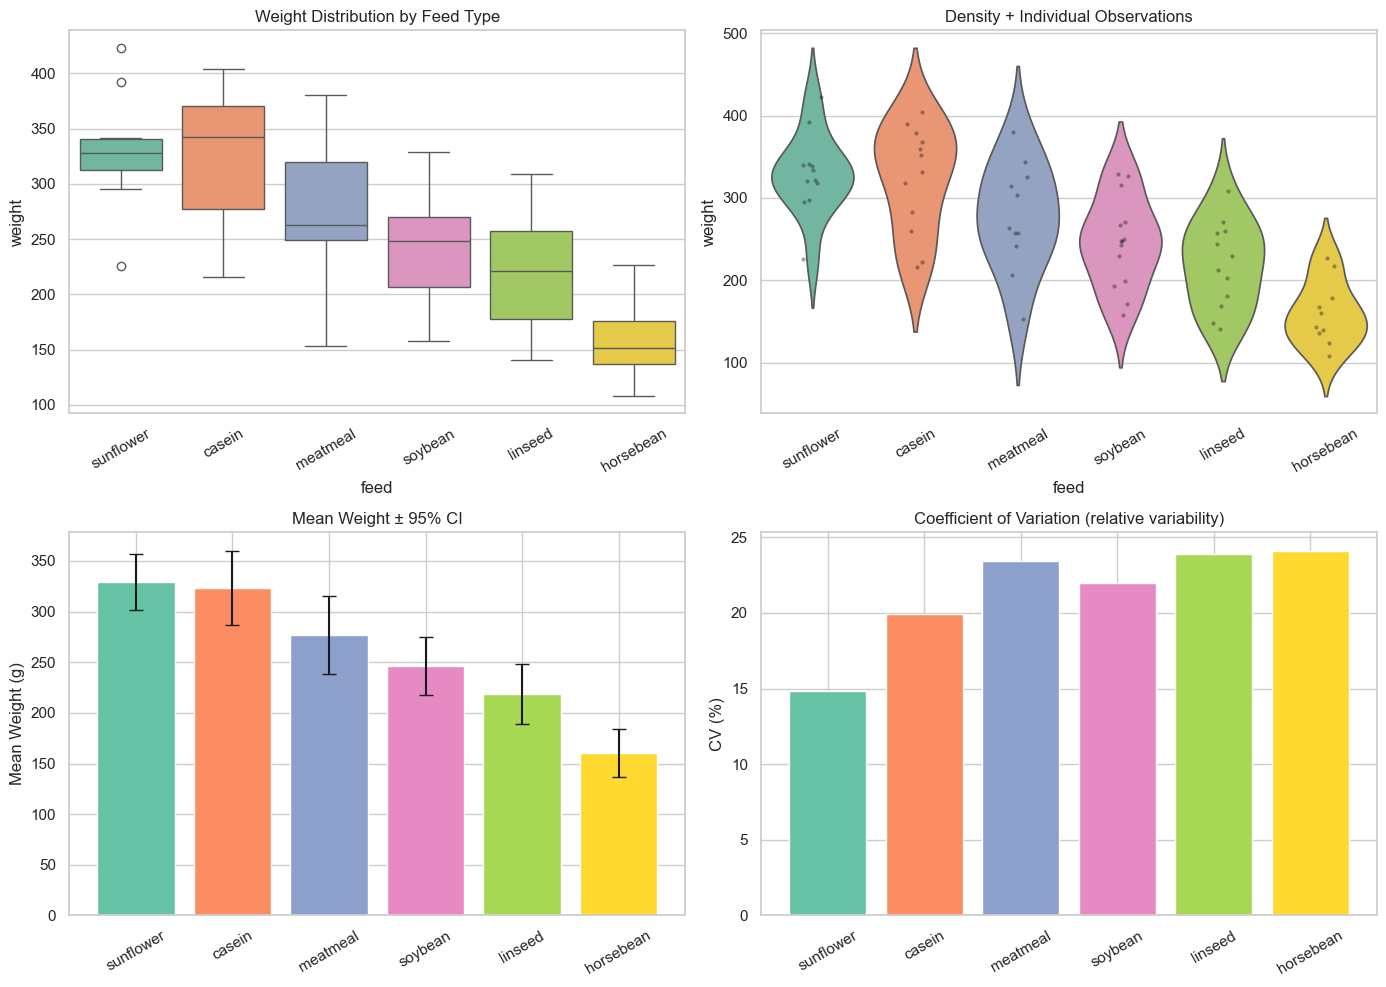

In [14]:
# Visual EDA
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Boxplot
order = summary.sort_values('mean', ascending=False).index
sns.boxplot(data=df, x='feed', y='weight', order=order, ax=axes[0,0], palette='Set2')
axes[0,0].set_title('Weight Distribution by Feed Type')
axes[0,0].tick_params(axis='x', rotation=30)

# Violin + strip
sns.violinplot(data=df, x='feed', y='weight', order=order, ax=axes[0,1], inner=None, palette='Set2')
sns.stripplot(data=df, x='feed', y='weight', order=order, ax=axes[0,1], color='k', alpha=0.4, size=3)
axes[0,1].set_title('Density + Individual Observations')
axes[0,1].tick_params(axis='x', rotation=30)

# Mean ± SE
means = summary.loc[order, 'mean']
ses = summary.loc[order, 'std'] / np.sqrt(summary.loc[order, 'count'])
axes[1,0].bar(range(len(order)), means, yerr=1.96*ses, capsize=5, color=sns.color_palette('Set2', len(order)))
axes[1,0].set_xticks(range(len(order)))
axes[1,0].set_xticklabels(order, rotation=30)
axes[1,0].set_ylabel('Mean Weight (g)')
axes[1,0].set_title('Mean Weight ± 95% CI')

# Coefficient of variation
cv = (summary['std'] / summary['mean'] * 100).loc[order]
axes[1,1].bar(range(len(order)), cv, color=sns.color_palette('Set2', len(order)))
axes[1,1].set_xticks(range(len(order)))
axes[1,1].set_xticklabels(order, rotation=30)
axes[1,1].set_ylabel('CV (%)')
axes[1,1].set_title('Coefficient of Variation (relative variability)')

plt.tight_layout()
plt.show()

The plots confirm the ordering of the feeds and show how much they overlap. Sunflower has a very narrow box, casein a wide box with a long lower tail, and horsebean sits clearly at the bottom. The confidence intervals of neighbouring feeds in the ranking overlap (casein with sunflower almost completely, and the middle feeds with each other), while feeds far apart in the ranking do not. The coefficient of variation panel shows that relative variability does not follow the ordering of the averages: sunflower is the most consistent feed and horsebean the least.

## Do the feeds really differ?


In [17]:
groups = [g["weight"].values for _, g in df.groupby("feed")]

f_stat, p_anova = stats.f_oneway(*groups)
residuals = df["weight"] - df.groupby("feed")["weight"].transform("mean")
shapiro = stats.shapiro(residuals)
levene = stats.levene(*groups)

grand_mean = df["weight"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((df["weight"] - grand_mean) ** 2).sum()

print(f"One-way ANOVA:        F = {f_stat:.2f}, p = {p_anova:.2e}")
print(f"Effect size (eta^2):  {ss_between / ss_total:.3f}  (share of weight variation explained by feed)")
print(f"Shapiro-Wilk on residuals (normality):     p = {shapiro.pvalue:.3f}")
print(f"Levene test (equal variances):             p = {levene.pvalue:.3f}")

One-way ANOVA:        F = 15.36, p = 5.94e-10
Effect size (eta^2):  0.542  (share of weight variation explained by feed)
Shapiro-Wilk on residuals (normality):     p = 0.627
Levene test (equal variances):             p = 0.590


The feeds clearly differ (ANOVA F = 15.36, p = 5.9e-10), and feed explains about 54% of the variation in weight (eta squared 0.542). Neither the normality test (p = 0.627) nor the equal-variance test (p = 0.590) gives any evidence against the ANOVA assumptions, so the group means and the Tukey comparisons below can be trusted. With only 10 to 14 birds per feed these tests have limited power, so passing them is reassurance rather than proof.

 But ANOVA only says that *some* feeds differ. Tukey's HSD compares **every pair** of feeds while controlling the overall error rate. A large p-value means that, given the noise in the data, we cannot tell the two feeds' average weights apart. This is an independent, statistically grounded view of "similar performance", and it is used later as **ground truth** to judge the recommender.

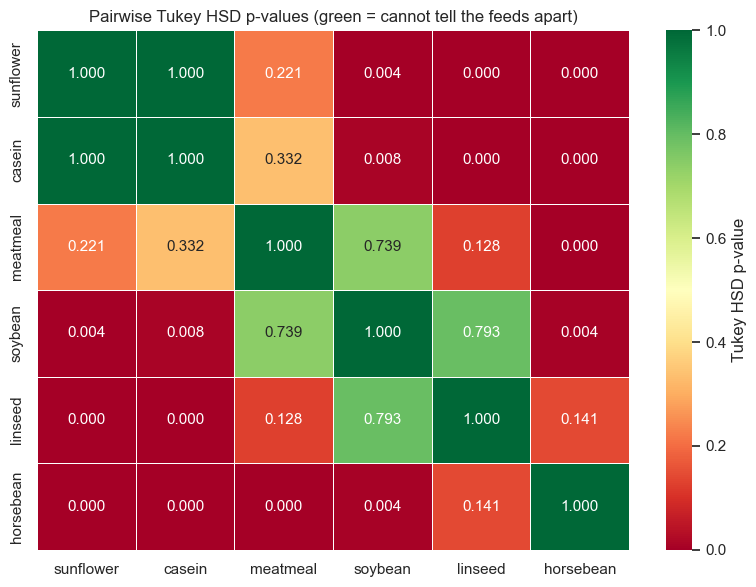

Pairs whose mean weights are statistically indistinguishable (p > 0.05):
  casein     - sunflower   p = 1.000
  linseed    - soybean     p = 0.793
  meatmeal   - soybean     p = 0.739
  casein     - meatmeal    p = 0.332
  meatmeal   - sunflower   p = 0.221
  horsebean  - linseed     p = 0.141
  linseed    - meatmeal    p = 0.128


In [18]:
feeds = sorted(df["feed"].unique())                       # fixed alphabetical order used throughout
weights = {f: df.loc[df["feed"] == f, "weight"].values.astype(float) for f in feeds}

tk = stats.tukey_hsd(*[weights[f] for f in feeds])
tukey_p = pd.DataFrame(tk.pvalue, index=feeds, columns=feeds)

plt.figure(figsize=(8, 6))
sns.heatmap(tukey_p.loc[feed_order, feed_order], annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Tukey HSD p-value"})
plt.title("Pairwise Tukey HSD p-values (green = cannot tell the feeds apart)")
plt.tight_layout()
plt.show()

similar_pairs = [(a, b, tukey_p.loc[a, b]) for i, a in enumerate(feeds) for b in feeds[i + 1:] if tukey_p.loc[a, b] > 0.05]
print("Pairs whose mean weights are statistically indistinguishable (p > 0.05):")
for a, b, p in sorted(similar_pairs, key=lambda t: -t[2]):
    print(f"  {a:10s} - {b:10s}  p = {p:.3f}")

Seven of the fifteen pairs cannot be told apart: casein and sunflower (p = 1.000), linseed and soybean (0.793), meatmeal and soybean (0.739), casein and meatmeal (0.332), meatmeal and sunflower (0.221), horsebean and linseed (0.141), and linseed and meatmeal (0.128). The other eight pairs differ significantly, for example horsebean against soybean (p = 0.004), and soybean against casein (0.008) and sunflower (0.004).

The structure is a **chain of overlapping groups**, not clean clusters: casein and sunflower at the top, meatmeal bridging down to soybean and linseed in the middle, and horsebean at the bottom, similar only to linseed. This gives a ground truth a good recommender should respect, for instance casein should be matched with sunflower and soybean with linseed or meatmeal. One caution: a large p-value means the data cannot separate two feeds, which is not the same as proving they are equal, especially with small samples.

# Data Preparation

In [19]:
def engineer_feed_features(w):
    """Summarise the weights of one feed into a performance profile."""
    s = pd.Series(w, dtype=float)
    return pd.Series({
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(ddof=1),
        "iqr": s.quantile(0.75) - s.quantile(0.25),
        "cv": s.std(ddof=1) / s.mean() * 100,
        "min": s.min(),
        "max": s.max(),
        "range": s.max() - s.min(),
        "q10": s.quantile(0.10),
        "q25": s.quantile(0.25),
        "q75": s.quantile(0.75),
        "q90": s.quantile(0.90),
        "skew": s.skew(),
        "kurtosis": s.kurt(),
    })


def build_feature_matrix(weights_by_feed):
    return pd.DataFrame({f: engineer_feed_features(w) for f, w in weights_by_feed.items()}).T.loc[feeds]


feature_matrix = build_feature_matrix(weights)

features_full = feature_matrix.columns.tolist()                                   # location + spread + shape (14)
features_perf = ["mean", "median", "min", "max", "q10", "q25", "q75", "q90"]      # location only (8)

print("Feature matrix (feeds x engineered statistics):")
display(feature_matrix.round(2))
print("Full profile:       ", len(features_full), "features")
print("Performance profile:", len(features_perf), "features (location statistics only)")

Feature matrix (feeds x engineered statistics):


,mean,median,std,iqr,cv,min,max,range,q10,q25,q75,q90,skew,kurtosis
casein,323.58,342.0,64.43,93.50,19.91,216.0,404.0,188.0,225.8,277.25,370.75,388.9,-0.60,-0.96
horsebean,160.20,151.5,38.63,39.25,24.11,108.0,227.0,119.0,122.4,137.00,176.25,218.0,0.65,-0.40
linseed,218.75,221.0,52.24,79.75,23.88,141.0,309.0,168.0,150.1,178.00,257.75,269.9,0.01,-0.88
meatmeal,276.91,263.0,64.90,70.50,23.44,153.0,380.0,227.0,206.0,249.50,320.00,344.0,-0.33,0.01
soybean,246.43,248.0,54.13,63.25,21.97,158.0,329.0,171.0,177.6,206.75,270.00,323.7,0.04,-0.71
sunflower,328.92,328.0,48.84,27.50,14.85,226.0,423.0,197.0,295.2,312.75,340.25,386.9,-0.07,1.75


Full profile:        14 features
Performance profile: 8 features (location statistics only)


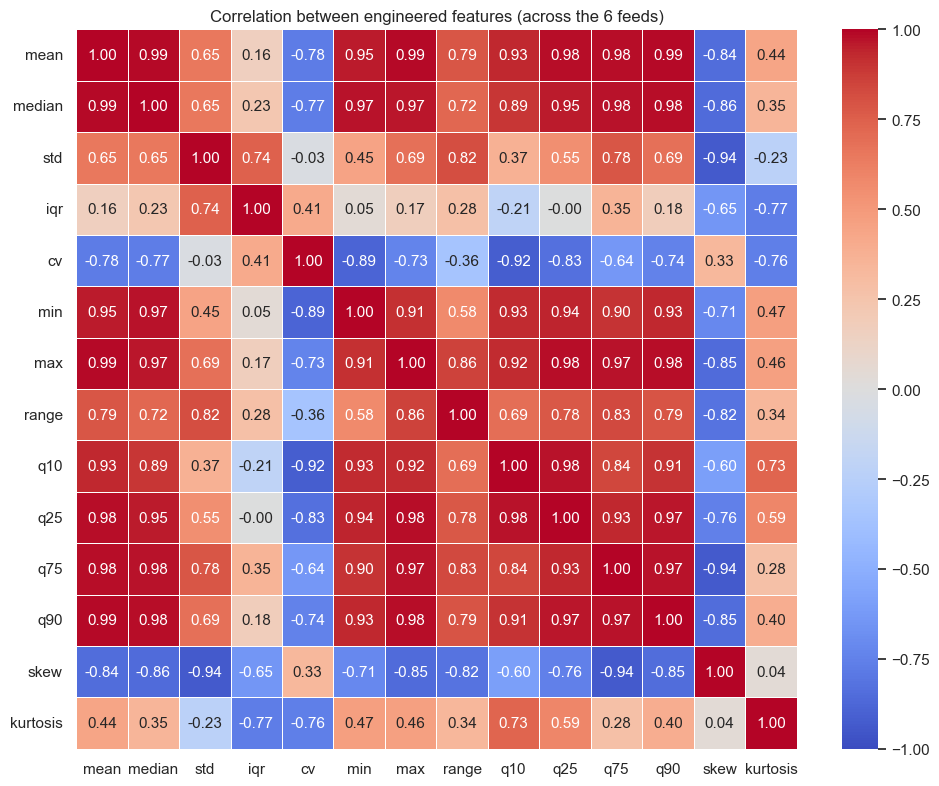

In [20]:
# How redundant are the engineered features?
plt.figure(figsize=(10, 8))
sns.heatmap(feature_matrix.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Correlation between engineered features (across the 6 feeds)")
plt.tight_layout()
plt.show()

The location statistics carry almost the same information: mean and median correlate at 0.99, and all eight location statistics (mean, median, min, max and the four percentiles) correlate between 0.84 and 0.99 with one another. The spread statistics are related too (standard deviation with IQR 0.74 and with range 0.82), and the CV moves against the mean (-0.78): feeds with lower averages have higher relative variability. Correlations across only six feeds are indicative at best, but they confirm the redundancy that PCA is designed to remove.

Two profiles are compared in the rest of the notebook: the **full profile** (14 statistics, as in the original design) and a **performance profile** (the 8 location statistics only). The hypothesis to test is that spread and shape statistics, estimated from only 10 to 14 birds, are noisy and may pull the map away from what the farmer cares about, the weight outcome.

# Modelling PCA and Similarity metrics